In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.linalg import null_space
from gauge_arbitrage.vf.vf_series import Vf_series
from gauge_arbitrage.vf import detector

# Day 3
Today I implemented the new version of the detector that will be used in the simulation phase, with extra parameters (`refresh`, `use_cash`). NOTE: when testing the new detector on the `Vf_series` data, set `use_cash=False` !!!!!!!!!! (or else everything will break because cash is already included). So basically the exact same thing as the last three weeks, except the names are different.

In [2]:
B=Vf_series(200, 200)
rng=np.random.default_rng(seed=0)

Text(0.5, 1.0, 'Simulation with 20 log-normal random walks (compare to V&F)')

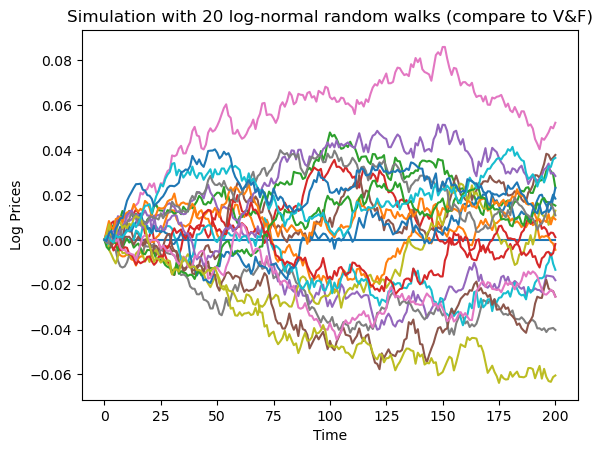

In [3]:
beta_a=rng.uniform(low=-0.0001, high=0.0001, size=(18))                                        #Randomly generate values for beta
sigma=np.insert(rng.uniform(low=-0.001, high=0.001, size=(20, 18)),0,  np.zeros(18), axis=0)   #Randomly generate values for sigma
alpha_A=rng.uniform(low=-0.0001, high=0.0001, size=(2))                                        #Randomly generate values for alpha_A
Z=rng.standard_normal((200, 18))                #Randomly generate values for Brownian motions (only 18 independent Brownian motions)
X=B.X_mu_43(sigma, beta_a, alpha_A, 1, Z)       #Create the time series according to Eq. (106)

#Compare to V&F Figure 1
fig_1, ax_1=plt.subplots(1,1)
rng2=np.random.default_rng()

#plot 20 random walks
for i in range(21):
    ax_1.plot(B.times, np.log(X[:, i]))
ax_1.set_xlabel('Time')
ax_1.set_ylabel('Log Prices')
ax_1.set_title('Simulation with 20 log-normal random walks (compare to V&F)')

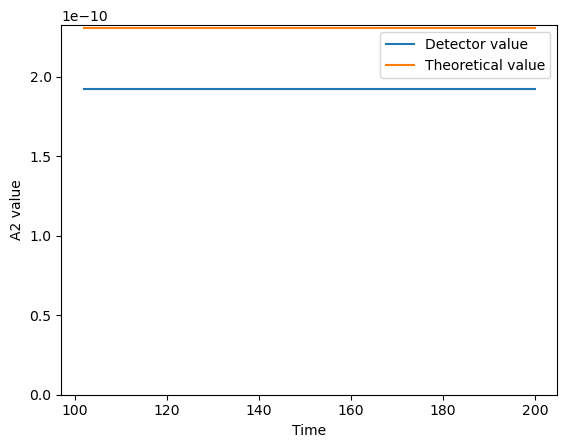

In [5]:
arr=detector.run_detector(detector.calc_R(X), L=100, refresh=5, n_dirs=2, use_cash=False)['products'] # Run the detector
A2_values=arr[~np.isnan(arr)] #Remove nan values (window)

#This plot should match V&F figure 2
fig, ax=plt.subplots(1,1)
ax.plot(B.times[102:], A2_values, label='Detector value')
ax.plot(B.times[102:], np.zeros(99)+(alpha_A@alpha_A), label='Theoretical value')
ax.set_ylim(0)
ax.set_xlabel('Time')
ax.set_ylabel('A2 value')
ax.legend()

In [36]:
def test_no_lookahead(R, t, **kw):
    """Replace every return from step t on with noise.
    Weights picked at refreshes up to t must not change."""
    rng = np.random.default_rng(0)
    R2 = R.copy(); R2[t:] = rng.standard_normal(R2[t:].shape)
    a, b = detector.run_detector(R, **kw), detector.run_detector(R2, **kw)
    k = 20   # number of refreshes completed at or before step t
    assert np.allclose(a["weights"][:k], b["weights"][:k])

In [37]:
test_no_lookahead(detector.calc_R(X), 195, L=100, refresh=5, n_dirs=2, use_cash=False)